# Avance 3: Integración, análisis descriptivo y diseño de un ETL reproducible

## Proyecto: Optimización del desempeño comercial en la industria de videojuegos

**Equipo:** Risk Analysts

**Alumno:** Hernández Martínez Ricardo

**Fecha:** 5 de noviembre de 2026

**Repositorio:** https://github.com/Richi0001/proyecto_Bi_Videojuegos

## 1. Continuidad con los avances anteriores

**Pregunta de negocio vigente:**
¿Qué combinaciones de género, plataforma y región han concentrado mayores ventas históricas entre 1980 y 2016, y qué patrones de distribución pueden servir de referencia para la toma de decisiones de inversión en nuevos proyectos de videojuegos?

**Decisión que se busca apoyar:**
Informar la toma de decisiones estratégicas sobre género, plataforma y región para nuevos proyectos, con base en patrones históricos de desempeño comercial.

**Fuente:** `vgsales.csv` (Kaggle, Gregorut, Pública).

**Ajustes derivados de la retroalimentación:**
- Cobertura real verificada: 1980-2016 (con atípicos en 2017 y 2020).
- Lenguaje ajustado: "desempeño comercial" en lugar de "éxito comercial".
- Pregunta reformulada hacia patrones históricos, no predicción.

**Variables necesarias:** `Genre`, `Platform`, `Year`, `Global_Sales`, `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`.

## 2. Contrato del ETL

| Aspecto | Definición |
|---|---|
| Fuente | `vgsales.csv`, 16,598 filas × 11 columnas |
| Unidad de observación | Un videojuego |
| Clave de negocio | `Rank` (identificador único por fila) |
| Integración | Una sola fuente; no se cruzan tablas |
| Entrada esperada | 11 columnas: Rank, Name, Platform, Year, Genre, Publisher, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales |
| Salida esperada | Datos válidos con tipos correctos + bitácora + pendientes |
| Cobertura | 1980-2016 (verificada en Avance 2) |
| Reproducibilidad | Funciones: extraer → normalizar → revisar → preparar → guardar |

In [4]:
from pathlib import Path
from datetime import datetime
import pandas as pd

# Columnas esperadas
COLUMNAS = [
    "Rank", "Name", "Platform", "Year", "Genre",
    "Publisher", "NA_Sales", "EU_Sales", "JP_Sales",
    "Other_Sales", "Global_Sales"
]

# Cargamos la fuente
entrada = Path("/content/data/raw/vgsales.csv")

print(f"Fuente disponible: {entrada.exists()}")

Fuente disponible: True


In [6]:
def extraer(archivo):

    #Lee el archivo vgsales.csv y verifica que las columnas coincidan.
    #Devuelve la tabla con las columnas en el orden definido.

    tabla = pd.read_csv(archivo)

    if set(tabla.columns) != set(COLUMNAS):
        raise ValueError(f"Columnas inesperadas. Se esperaban {COLUMNAS}")

    return tabla[COLUMNAS]

crudos = extraer(entrada)
print(f"Filas: {len(crudos)}")
print(f"Columnas: {len(crudos.columns)}")
print(f"Primer registro: {crudos.iloc[0].to_dict()}")

Filas: 16598
Columnas: 11
Primer registro: {'Rank': 1, 'Name': 'Wii Sports', 'Platform': 'Wii', 'Year': 2006.0, 'Genre': 'Sports', 'Publisher': 'Nintendo', 'NA_Sales': 41.49, 'EU_Sales': 29.02, 'JP_Sales': 3.77, 'Other_Sales': 8.46, 'Global_Sales': 82.74}


In [7]:
# Bitácora automática
bitacora = []

def anotar(paso, antes, despues, regla, resultado, observaciones, responsable="Ricardo"):

    #Registra una operación del ETL en la bitácora.
    #Campos: fecha, archivo, paso, filas_antes, filas_despues,
    #detalle, responsable, regla, resultado, observaciones.

    bitacora.append({
        "fecha": datetime.now().astimezone().isoformat(),
        "archivo": str(entrada.name),
        "paso": paso,
        "filas_antes": antes,
        "filas_despues": despues,
        "regla": regla,
        "resultado": resultado,
        "observaciones": observaciones,
        "responsable": responsable
    })

# Primera anotación: lectura
anotar(
    paso="leer",
    antes=len(crudos),
    despues=len(crudos),
    regla="Verificar 11 columnas esperadas",
    resultado="Correcto",
    observaciones="Entrada conservada sin modificaciones"
)

print("Bitácora inicial:")
print(pd.DataFrame(bitacora).to_string(index=False))

Bitácora inicial:
                           fecha     archivo paso  filas_antes  filas_despues                           regla resultado                         observaciones responsable
2026-11-07T08:07:12.440124+00:00 vgsales.csv leer        16598          16598 Verificar 11 columnas esperadas  Correcto Entrada conservada sin modificaciones     Ricardo


## 3. Deduplicación y normalización

**Deduplicación:** en el Avance 2 se verificó que `vgsales.csv` no tiene duplicados exactos. Aun así, el ETL incluye el paso `drop_duplicates()` para dejar constancia y por si una futura entrega del archivo los tuviera.

**Normalización:** se aplican dos reglas justificadas:
1. `Year` está como `float64` porque contiene 271 nulos. Convertir a `Int64` (entero anulable) para representar años correctamente sin perder los nulos.
2. Las columnas de texto (`Name`, `Platform`, `Genre`, `Publisher`) se limpian con `.str.strip()` para eliminar espacios accidentales al inicio o al final. No se cambian mayúsculas ni contenido.

**No se normalizan:** las columnas de ventas (`NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`, `Global_Sales`) porque ya están en `float64` y todas en millones de copias. `Rank` ya es `int64`.

In [8]:
# 1. Deduplicación
sin_repetir = crudos.drop_duplicates().copy()

anotar(
    paso="retirar_repetidas",
    antes=len(crudos),
    despues=len(sin_repetir),
    regla="Eliminar duplicados exactos",
    resultado="Correcto" if len(crudos) == len(sin_repetir) else "Con observaciones",
    observaciones=f"{len(crudos) - len(sin_repetir)} filas retiradas"
)

# 2. Normalización
def normalizar(tabla):
    resultado = tabla.copy()
    # Year: float64 -> Int64 (manejo de nulos)
    resultado["Year"] = resultado["Year"].astype("Int64")
    # Texto: strip
    for col in ["Name", "Platform", "Genre", "Publisher"]:
        resultado[col] = resultado[col].astype("string").str.strip()
    return resultado

normalizados = normalizar(sin_repetir)

anotar(
    paso="normalizar",
    antes=len(sin_repetir),
    despues=len(normalizados),
    regla="Year a Int64; texto con strip",
    resultado="Correcto",
    observaciones=f"Year dtype: {normalizados['Year'].dtype}"
)

print(f"Crudos: {len(crudos)}")
print(f"Sin repetir: {len(sin_repetir)}")
print(f"Normalizados: {len(normalizados)}")
print(f"Year tipo: {normalizados['Year'].dtype}")
print(f"Ejemplo Year: {normalizados['Year'].head(5).tolist()}")

Crudos: 16598
Sin repetir: 16598
Normalizados: 16598
Year tipo: Int64
Ejemplo Year: [2006, 1985, 2008, 2009, 1996]


## 4. Validación por regla

Se definen **7 reglas**, cada una produce un booleano por fila:

**Reglas bloqueantes** (si falla, la fila pasa a pendientes):
1. `rank_valido`: Rank > 0
2. `name_presente`: Name no vacío
3. `platform_presente`: Platform no vacío
4. `genre_presente`: Genre no vacío
5. `global_sales_valido`: Global_Sales ≥ 0

**Reglas no bloqueantes** (se reportan pero no excluyen):
6. `year_presente`: Year no nulo
7. `publisher_presente`: Publisher no nulo

**Justificación:** el dataset está limpio en sus columnas esenciales. Las ausencias en `Year` (271) y `Publisher` (58) son conocidas y no impiden el análisis por género, plataforma o ventas. Se reportan como limitación, no como motivo de exclusión.

In [9]:
def revisar(tabla):
    controles = pd.DataFrame({
        "rank_valido": tabla["Rank"] > 0,
        "name_presente": tabla["Name"].notna() & tabla["Name"].str.strip().ne(""),
        "platform_presente": tabla["Platform"].notna() & tabla["Platform"].str.strip().ne(""),
        "genre_presente": tabla["Genre"].notna() & tabla["Genre"].str.strip().ne(""),
        "global_sales_valido": tabla["Global_Sales"] >= 0,
        "year_presente": tabla["Year"].notna(),
        "publisher_presente": tabla["Publisher"].notna(),
    })
    return controles.fillna(False)

controles = revisar(normalizados)

print(f"Filas evaluadas: {len(controles)}")
print(f"Reglas: {list(controles.columns)}")
print("\nFilas que cumplen cada regla:")
print(controles.sum().to_string())

anotar(
    paso="revisar",
    antes=len(normalizados),
    despues=len(normalizados),
    regla="Aplicar 7 reglas de calidad (5 bloqueantes + 2 reportables)",
    resultado="Con observaciones",
    observaciones=f"Year nulos: {(~controles['year_presente']).sum()}; Publisher nulos: {(~controles['publisher_presente']).sum()}"
)

Filas evaluadas: 16598
Reglas: ['rank_valido', 'name_presente', 'platform_presente', 'genre_presente', 'global_sales_valido', 'year_presente', 'publisher_presente']

Filas que cumplen cada regla:
rank_valido            16598
name_presente          16598
platform_presente      16598
genre_presente         16598
global_sales_valido    16598
year_presente          16327
publisher_presente     16540


## 5. Separación de válidos y pendientes

**Criterio:** una fila es válida si cumple **todas las reglas bloqueantes** (Rank > 0, Name/Platform/Genre presentes, Global_Sales ≥ 0). Las reglas reportables (`year_presente`, `publisher_presente`) no excluyen, solo documentan limitaciones.

**Resultado esperado:** todas las filas son válidas. No hay pendientes por reglas bloqueantes. Las 271 filas sin `Year` y las 58 sin `Publisher` se conservan en válidos y se reportan como observaciones.

**Subconjunto temporal:** para el análisis por año se usará `analisis_temporal` (16,327 filas), que excluye solo las 271 sin `Year`. Esto se hace en la sección de estadística, no aquí.

In [12]:
# Reglas bloqueantes
reglas_bloqueantes = [
    "rank_valido", "name_presente", "platform_presente",
    "genre_presente", "global_sales_valido"
]

cumple_bloqueantes = controles[reglas_bloqueantes].all(axis=1)

validos = normalizados.loc[cumple_bloqueantes].copy()
pendientes = normalizados.loc[~cumple_bloqueantes].copy()

print(f"Válidos: {len(validos)}")
print(f"Pendientes: {len(pendientes)}")
print(f"Total: {len(validos) + len(pendientes)}")

anotar(
    paso="separar",
    antes=len(normalizados),
    despues=len(validos),
    regla="5 reglas bloqueantes (Rank, Name, Platform, Genre, Global_Sales)",
    resultado="Correcto",
    observaciones=f"Pendientes: {len(pendientes)}; observaciones: {(~controles['year_presente']).sum()} sin Year, {(~controles['publisher_presente']).sum()} sin Publisher"
)

Válidos: 16598
Pendientes: 0
Total: 16598


## 6. Columna derivada

Se agrega una columna derivada con regla explícita:

- **`decada`**: década del año de lanzamiento, calculada como `(Year // 10) * 10`. Solo se calcula cuando `Year` no es nulo. Valores posibles: 1980, 1990, 2000, 2010. Sirve para agrupar el análisis por periodo histórico.

**No se agregan más columnas derivadas** para no inventar variables sin respaldo en la pregunta de negocio. Las columnas de ventas ya están en millones de copias y no requieren conversión.

In [14]:
def preparar(tabla):
    salida = tabla[COLUMNAS].copy()

    # Columna derivada: década del año
    salida["decada"] = (salida["Year"] // 10 * 10).astype("Int64")
    return salida.sort_values("Rank").reset_index(drop=True)

listos = preparar(validos)

anotar(
    paso="preparar",
    antes=len(validos),
    despues=len(listos),
    regla="Agregar columna derivada 'decada' y ordenar por Rank",
    resultado="Correcto",
    observaciones=f"Columnas finales: {list(listos.columns)}"
)

print(f"Filas: {len(listos)}")
print(f"Columnas: {list(listos.columns)}")
print("\nPrimeras 5 filas:")
print(listos.head(5).to_string(index=False))
print("\nValores de 'decada':")
print(listos["decada"].value_counts(dropna=False).sort_index().to_string())

Filas: 16598
Columnas: ['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'decada']

Primeras 5 filas:
 Rank                     Name Platform  Year        Genre Publisher  NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  decada
    1               Wii Sports      Wii  2006       Sports  Nintendo     41.49     29.02      3.77         8.46         82.74    2000
    2        Super Mario Bros.      NES  1985     Platform  Nintendo     29.08      3.58      6.81         0.77         40.24    1980
    3           Mario Kart Wii      Wii  2008       Racing  Nintendo     15.85     12.88      3.79         3.31         35.82    2000
    4        Wii Sports Resort      Wii  2009       Sports  Nintendo     15.75     11.01      3.28         2.96         33.00    2000
    5 Pokemon Red/Pokemon Blue       GB  1996 Role-Playing  Nintendo     11.27      8.89     10.22         1.00         31.37    1990

Valores de 'decad

## 7. Análisis estadístico descriptivo

Se eligen **5 medidas** adecuadas para la pregunta de negocio. Cada una de ellas responde a una pregunta analítica concreta, se calcula en Python y se interpreta junto con los patrones históricos de ventas.

| # | Pregunta analítica | Variables | Medida | Justificación |
|---|---|---|---|---|
| 1 | ¿Cómo se distribuyen las ventas globales por género? | Genre, Global_Sales | Media y mediana | Comparar centros entre géneros; la mediana es robusta a atípicos |
| 2 | ¿Qué plataformas tienen mayor variabilidad en ventas? | Platform, Global_Sales | Desviación estándar | Identificar plataformas con ventas homogéneas vs dispersas |
| 3 | ¿Qué géneros concentran más lanzamientos? | Genre | Frecuencias absolutas y porcentajes | Ver la oferta histórica por género |
| 4 | ¿Cómo se distribuyen las ventas globales? | Global_Sales | Percentiles (25, 50, 75, 90, 99) | Ver forma de la distribución y concentración |
| 5 | ¿Existe asociación lineal entre ventas de NA y EU? | NA_Sales, EU_Sales | Correlación de Pearson | Explorar si los mercados occidentales se mueven juntos |

**Nota:** las 5 medidas se calculan sobre `listos` (16,598 filas). No dependen del año, así que los 4 registros atípicos de 2017-2020 no sesgan los resultados. Se documentan como limitación de cobertura, no como motivo de exclusión.

In [15]:
# Medida 1: Media y mediana de Global_Sales por género
medida_1 = (
    listos.groupby("Genre", as_index=False)
    .agg(
        juegos=("Rank", "size"),
        media_global=("Global_Sales", "mean"),
        mediana_global=("Global_Sales", "median"),
        total_global=("Global_Sales", "sum")
    )
    .sort_values("media_global", ascending=False)
    .round(2)
)
print("=== Medida 1: Media y mediana de ventas globales por género ===")
print(medida_1.to_string(index=False))

# Medida 2: Desviación estándar de Global_Sales por plataforma (top 10 por número de juegos)
top_plataformas = listos["Platform"].value_counts().head(10).index.tolist()
medida_2 = (
    listos[listos["Platform"].isin(top_plataformas)]
    .groupby("Platform", as_index=False)
    .agg(
        juegos=("Rank", "size"),
        media_global=("Global_Sales", "mean"),
        desv_std=("Global_Sales", "std")
    )
    .sort_values("juegos", ascending=False)
    .round(2)
)
print("\n=== Medida 2: Desviación estándar de ventas globales (top 10 plataformas) ===")
print(medida_2.to_string(index=False))

# Medida 3: Frecuencias de género
medida_3 = (
    listos["Genre"]
    .value_counts()
    .rename_axis("Genre")
    .reset_index(name="frecuencia")
)
medida_3["porcentaje"] = (medida_3["frecuencia"] / len(listos) * 100).round(2)
print("\n=== Medida 3: Frecuencias de género ===")
print(medida_3.to_string(index=False))

=== Medida 1: Media y mediana de ventas globales por género ===
       Genre  juegos  media_global  mediana_global  total_global
    Platform     886          0.94            0.28        831.37
     Shooter    1310          0.79            0.23       1037.37
Role-Playing    1488          0.62            0.18        927.37
      Racing    1249          0.59            0.19        732.04
      Sports    2346          0.57            0.22       1330.93
    Fighting     848          0.53            0.21        448.91
      Action    3316          0.53            0.19       1751.18
        Misc    1739          0.47            0.16        809.96
  Simulation     867          0.45            0.16        392.20
      Puzzle     582          0.42            0.11        244.95
    Strategy     681          0.26            0.09        175.12
   Adventure    1286          0.19            0.06        239.04

=== Medida 2: Desviación estándar de ventas globales (top 10 plataformas) ===
Platform  ju

In [16]:
# Medida 4: Percentiles de Global_Sales
percentiles = [0.25, 0.50, 0.75, 0.90, 0.99]
medida_4 = listos["Global_Sales"].quantile(percentiles).round(4).to_frame(name="Global_Sales")
medida_4.index.name = "percentil"
print("=== Medida 4: Percentiles de ventas globales ===")
print(medida_4.to_string())

# Medida 5: Correlación de Pearson entre NA_Sales y EU_Sales
r = listos["NA_Sales"].corr(listos["EU_Sales"], method="pearson")
medida_5 = pd.DataFrame({
    "par": ["NA_Sales vs EU_Sales"],
    "n": [len(listos)],
    "pearson": [round(r, 4)]
})
print("\n=== Medida 5: Correlación de Pearson entre ventas NA y EU ===")
print(medida_5.to_string(index=False))

=== Medida 4: Percentiles de ventas globales ===
           Global_Sales
percentil              
0.25             0.0600
0.50             0.1700
0.75             0.4700
0.90             1.2100
0.99             5.4306

=== Medida 5: Correlación de Pearson entre ventas NA y EU ===
                 par     n  pearson
NA_Sales vs EU_Sales 16598   0.7677


## 8. Interpretación de las medidas

**Medida 1 — Media y mediana de ventas globales por género:**
El género con mayor media es Platform (0.94 Millones de copias) y el de mayor mediana también es Platform (0.28 Millones). El género más frecuente, Action (3,316 juegos), tiene una media de 0.53 Millones y una mediana de 0.19 Millones, por debajo de Platform y Shooter.

Adventure es el género con peor desempeño (media 0.19 Millones, mediana 0.06 Millones). En todos los géneros la mediana es menor que la media, lo que confirma una distribución sesgada a la derecha:

Unos pocos juegos venden muchísimo, pero la mayoría vende poco. Para la pregunta de negocio, apostar por el género más frecuente no garantiza mayores ventas promedio. La decisión depende de si se busca un éxito masivo (media alta) o un desempeño típico (mediana alta).

**Medida 2 — Desviación estándar de ventas globales por plataforma:**
La plataforma con mayor desviación estándar es Wii (S=3.14) lo que indica una baja concentración en los datos, muy por encima del resto.

Le siguen X360 (S=1.62), DS (S=1.43) y PS3 (S=1.41). De las cuales las más homogéneas son PSP (S=0.52) y XB (S=0.53). Una desviación alta indica que en esa plataforma conviven juegos con ventas muy altas y juegos con ventas muy bajas. Para la pregunta de negocio, una plataforma con alta variabilidad ofrece mayor potencial de éxito masivo, pero también mayor riesgo. Wii es la más volátil: puede producir el juego más vendido de la historia (Wii Sports, 82.74 Millones) o fracasos.

**Medida 3 — Frecuencias de género:**
El género Action concentra la mayor cantidad de lanzamientos (3,316 juegos, 19.98%), seguido de Sports (2,346, 14.13%) y Misc (1,739, 10.48%). Puzzle es el menos frecuente (582, 3.51%).

Esto refleja la oferta histórica de la industria, no necesariamente la rentabilidad. Un género con muchos lanzamientos tiene más competencia. Para la pregunta de negocio, conviene considerar que los géneros más frecuentes no son los de mayor media:

Action tiene media 0.53 Millones, mientras Platform (886 juegos) tiene media 0.94 Millones.

**Medida 4 — Percentiles de ventas globales:**
El 50% de los juegos vende menos de 0.17 Millones de copias.

El 75% vende menos de 0.47 Millones.

El 90% vende menos de 1.21 Millones.

Solo el 1% supera los 5.43 Millones.

La distribución está muy concentrada ya que con pocos juegos explicamos la mayor parte de las ventas. Cualquier decisión de inversión debe asumir que la mayoría de los juegos vende poco, y que el retorno depende de unos pocos éxitos.

**Medida 5 — Correlación de Pearson (NA vs EU):**


r = 0.7677.

Es una correlación lineal positiva fuerte entre las ventas de Norteamérica y Europa, los dos mercados occidentales tienden a moverse juntos:

Un juego exitoso en NA por lo regular también lo es en EU, pero eso no es suficiente para afirmar ni demuestra causalidad, no significa que vender en NA genere ventas en EU. Solo describe una asociación histórica. Para la pregunta de negocio, esto puede apoyar la idea de que una estrategia para mercados occidentales puede tener alcance regional amplio, no solo en un país.

In [19]:
# Corrección: buscar el máximo real de desv_std, no la primera fila
fila_desv_max = medida_2.loc[medida_2['desv_std'].idxmax()]

resumen_medidas = pd.DataFrame({
    "Medida": [1, 2, 3, 4, 5],
    "Pregunta": [
        "Ventas por género",
        "Variabilidad por plataforma",
        "Frecuencias de género",
        "Percentiles de ventas",
        "Correlación NA-EU"
    ],
    "Variables": [
        "Genre, Global_Sales",
        "Platform, Global_Sales",
        "Genre",
        "Global_Sales",
        "NA_Sales, EU_Sales"
    ],
    "Estadístico": [
        "Media y mediana",
        "Desviación estándar",
        "Frecuencias y porcentajes",
        "Percentiles 25, 50, 75, 90, 99",
        "Pearson"
    ],
    "Resultado": [
        f"Media máx: {medida_1.iloc[0]['media_global']} ({medida_1.iloc[0]['Genre']})",
        f"Desv. máx: {fila_desv_max['desv_std']} ({fila_desv_max['Platform']})",
        f"Género más frecuente: {medida_3.iloc[0]['Genre']} ({medida_3.iloc[0]['porcentaje']}%)",
        f"Mediana: {medida_4.loc[0.50, 'Global_Sales']} Millones",
        f"r = {medida_5.iloc[0]['pearson']}"
    ]
})
print("=== Matriz resumen de las 5 medidas ===\n\n")
print(resumen_medidas.to_string(index=False))

anotar(
    paso="analisis_estadistico",
    antes=len(listos),
    despues=len(listos),
    regla="Calcular 5 medidas descriptivas sobre datos preparados",
    resultado="Correcto",
    observaciones="Media/mediana por género, desv. std por plataforma, frecuencias, percentiles, correlación NA-EU"
)

=== Matriz resumen de las 5 medidas ===


 Medida                    Pregunta              Variables                    Estadístico                             Resultado
      1           Ventas por género    Genre, Global_Sales                Media y mediana            Media máx: 0.94 (Platform)
      2 Variabilidad por plataforma Platform, Global_Sales            Desviación estándar                 Desv. máx: 3.14 (Wii)
      3       Frecuencias de género                  Genre      Frecuencias y porcentajes Género más frecuente: Action (19.98%)
      4       Percentiles de ventas           Global_Sales Percentiles 25, 50, 75, 90, 99                Mediana: 0.17 Millones
      5           Correlación NA-EU     NA_Sales, EU_Sales                        Pearson                            r = 0.7677


## 9. Conciliación de conteos

Toda fila recibida debe quedar explicada una sola vez. La conciliación es:

**N_crudos = N_repetidas + N_válidos + N_pendientes**

16598 = 0 + 16598 + 0


La tabla `listos` deriva de `válidos`, no se suma nuevamente. La columna `decada` es derivada y no agrega filas. El subconjunto `analisis_temporal` (16,327 filas) se usará después para análisis por año, pero no forma parte de la conciliación del ETL.

In [21]:
n_crudos = len(crudos)
n_repetidas = len(crudos) - len(sin_repetir)
n_validos = len(validos)
n_pendientes = len(pendientes)
n_listos = len(listos)

cuadra = (n_crudos == n_repetidas + n_validos + n_pendientes)

print("=== Conciliación de conteos ===\n\n")
print(f"Crudos recibidos: {n_crudos}")
print(f"Repetidas retiradas: {n_repetidas}")
print(f"Válidos: {n_validos}")
print(f"Pendientes: {n_pendientes}")
print(f"Listos (derivan de válidos): {n_listos}")
print(f"\n¿Cuadra? {n_crudos} = {n_repetidas} + {n_validos} + {n_pendientes} → {cuadra}")

assert cuadra, "La conciliación no cuadra"
assert n_listos == n_validos, "Listos debe ser igual a válidos (solo se agregó columna derivada)"

anotar(
    paso="conciliar",
    antes=n_crudos,
    despues=n_validos,
    regla="N_crudos = N_repetidas + N_válidos + N_pendientes",
    resultado="Correcto" if cuadra else "Con observaciones",
    observaciones=f"{n_crudos} = {n_repetidas} + {n_validos} + {n_pendientes}"
)

=== Conciliación de conteos ===


Crudos recibidos: 16598
Repetidas retiradas: 0
Válidos: 16598
Pendientes: 0
Listos (derivan de válidos): 16598

¿Cuadra? 16598 = 0 + 16598 + 0 → True


In [22]:
nombre_carpeta = datetime.now().strftime("%Y%m%d_%H%M%S")
carpeta_salida = Path("/content/processed") / nombre_carpeta
carpeta_salida.mkdir(parents=True, exist_ok=True)

ruta_listos = carpeta_salida / "listos.csv"
listos.to_csv(ruta_listos, index=False)

ruta_pendientes = carpeta_salida / "pendientes.csv"
pendientes.to_csv(ruta_pendientes, index=False)

ruta_controles = carpeta_salida / "controles.csv"
controles.to_csv(ruta_controles, index=False)

anotar(
    paso="guardar",
    antes=len(listos),
    despues=len(listos),
    regla="Exportar listos.csv, pendientes.csv y controles.csv",
    resultado="Correcto",
    observaciones=f"Carpeta: {carpeta_salida.name}"
)

print(f"Carpeta de salida: {carpeta_salida}")
print(f"Archivos generados:")
for archivo in sorted(carpeta_salida.glob("*.csv")):
    print(f"  - {archivo.name} ({archivo.stat().st_size} bytes)")

Carpeta de salida: /content/processed/20261107_083855
Archivos generados:
  - controles.csv (581371 bytes)
  - listos.csv (1491181 bytes)
  - pendientes.csv (92 bytes)


In [23]:
df_bitacora = pd.DataFrame(bitacora)
ruta_bitacora = carpeta_salida / "bitacora.csv"
df_bitacora.to_csv(ruta_bitacora, index=False)

print("=== Bitácora completa del ETL ===\n\n")
print(df_bitacora[["paso", "filas_antes", "filas_despues", "resultado"]].to_string(index=False))
print(f"\nBitácora guardada en: {ruta_bitacora.name}")
print(f"Total de pasos registrados: {len(df_bitacora)}")

=== Bitácora completa del ETL ===


                paso  filas_antes  filas_despues         resultado
                leer        16598          16598          Correcto
   retirar_repetidas        16598          16598          Correcto
          normalizar        16598          16598          Correcto
             revisar        16598          16598 Con observaciones
             separar        16598          16598          Correcto
            preparar        16598          16598          Correcto
            preparar        16598          16598          Correcto
analisis_estadistico        16598          16598          Correcto
analisis_estadistico        16598          16598          Correcto
analisis_estadistico        16598          16598          Correcto
           conciliar        16598          16598          Correcto
           conciliar        16598          16598          Correcto
             guardar        16598          16598          Correcto

Bitácora guardada en: bit

In [28]:
listos_releidos = pd.read_csv(ruta_listos)

print("=== Verificación de relectura ===\n\n")
print(f"Filas: {len(listos_releidos)}")
print(f"Columnas: {list(listos_releidos.columns)}")
print(f"\n¿Mismo número de filas? {len(listos_releidos) == len(listos)}")

bitacora_releida = pd.read_csv(ruta_bitacora)
print(f"\nBitácora releída: {len(bitacora_releida)} pasos")
print(f"Columnas de bitácora: {list(bitacora_releida.columns)}")

columnas_esperadas = COLUMNAS + ["decada"]
assert set(listos_releidos.columns) == set(columnas_esperadas), "Faltan columnas en listos.csv"
assert len(bitacora_releida) == len(bitacora), "Bitácora incompleta"

print("\nTodas las verificaciones pasaron")

=== Verificación de relectura ===


Filas: 16598
Columnas: ['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'decada']

¿Mismo número de filas? True

Bitácora releída: 13 pasos
Columnas de bitácora: ['fecha', 'archivo', 'paso', 'filas_antes', 'filas_despues', 'regla', 'resultado', 'observaciones', 'responsable']

Todas las verificaciones pasaron


## 10. Integración: justificación de una sola fuente

El proyecto trabaja con **una sola fuente**: `vgsales.csv` (Kaggle, Gregorut, Pública). No se cruzan tablas ni se integran lotes porque no existen fuentes adicionales necesarias para responder la pregunta de negocio.

La guía del Avance 3 indica que "si el proyecto utiliza una sola fuente, no es obligatorio inventar un cruce o catálogo", por lo que no se fuerzan operaciones de `merge` o `concat` si no son indispensables.

**Integración interna aplicada:**
- La fuente ya es una tabla limpia (una fila por videojuego).
- No hay lotes separados que requieran `concat`.
- No hay catálogos externos que requieran `merge`.
- La única transformación de integración es la **consolidación interna** del archivo en un DataFrame, más la derivación de la columna `decada` a partir de `Year`.

**Cardinalidad esperada:** 1 fila por videojuego (16,598 registros), no hay duplicación por cruce.

**Alternativa descartada:** la fuente `videoGameSalesWithRatings.csv` se evaluó en el Avance 1 como alternativa, pero se decidió descartarla por sus altos faltantes en calificaciones (Critic_Score: 8,582; User_Score: 6,704), además de que no aporta variables necesarias para la pregunta de negocio.

In [29]:
print("=== Verificación del contrato de salida ===\n")

# 1. Columnas esperadas
columnas_esperadas = COLUMNAS + ["decada"]
cumple_columnas = set(listos.columns) == set(columnas_esperadas)
print(f"1. Columnas (12 esperadas): {cumple_columnas}")

# 2. Tipos de datos
tipos_esperados = {
    "Rank": "int64",
    "Year": "Int64",
    "NA_Sales": "float64",
    "EU_Sales": "float64",
    "JP_Sales": "float64",
    "Other_Sales": "float64",
    "Global_Sales": "float64",
    "decada": "Int64"
}
cumple_tipos = all(str(listos[col].dtype) == tipo for col, tipo in tipos_esperados.items())
print(f"2. Tipos de datos: {cumple_tipos}")

# 3. Rangos
cumple_rangos = (listos["Global_Sales"] >= 0).all() and (listos["Rank"] > 0).all()
print(f"3. Rangos (Global_Sales >= 0, Rank > 0): {cumple_rangos}")

# 4. Categorías no vacías
cumple_categorias = (
    listos["Genre"].notna().all()
    and listos["Platform"].notna().all()
    and (listos["Genre"].str.strip() != "").all()
    and (listos["Platform"].str.strip() != "").all()
)
print(f"4. Categorías (Genre, Platform no vacíos): {cumple_categorias}")

# 5. Clave única
cumple_clave = listos["Rank"].is_unique
print(f"5. Clave única (Rank): {cumple_clave}")

# Resultado global
contrato_ok = all([cumple_columnas, cumple_tipos, cumple_rangos, cumple_categorias, cumple_clave])
print(f"\n¿Contrato de salida completo? {contrato_ok}")

assert contrato_ok, "El contrato de salida no se cumple"
print("\nContrato de salida verificado.")

=== Verificación del contrato de salida ===

1. Columnas (12 esperadas): True
2. Tipos de datos: True
3. Rangos (Global_Sales >= 0, Rank > 0): True
4. Categorías (Genre, Platform no vacíos): True
5. Clave única (Rank): True

¿Contrato de salida completo? True

Contrato de salida verificado.


In [31]:
print("=== Prueba de reproducibilidad ===\n")

# Re-ejecutar el proceso completo desde la fuente original
crudos_test = extraer(entrada)
sin_repetir_test = crudos_test.drop_duplicates().copy()
normalizados_test = normalizar(sin_repetir_test)
controles_test = revisar(normalizados_test)

reglas_bloqueantes_test = [
    "rank_valido", "name_presente", "platform_presente",
    "genre_presente", "global_sales_valido"
]
validos_test = normalizados_test.loc[
    controles_test[reglas_bloqueantes_test].all(axis=1)
].copy()
listos_test = preparar(validos_test)

# Comparaciones
print(f"Filas en listos original: {len(listos)}")
print(f"Filas en listos reproducido: {len(listos_test)}")
print(f"¿Mismas filas? {len(listos) == len(listos_test)}")

columnas_iguales = set(listos.columns) == set(listos_test.columns)
print(f"¿Mismas columnas? {columnas_iguales}")

valores_iguales = listos.reset_index(drop=True).equals(
    listos_test.reset_index(drop=True)
)
print(f"¿Mismos valores? {valores_iguales}")

reproducible = columnas_iguales and valores_iguales and (len(listos) == len(listos_test))
print(f"\n¿Proceso reproducible? {reproducible}")

assert reproducible, "El proceso no es reproducible"

print("\nEl proceso ETL es reproducible.")
print("\nMisma entrada + mismas reglas = misma salida.")
print("\nLa bitácora y la carpeta cambian de fecha, pero el contenido es idéntico.")

=== Prueba de reproducibilidad ===

Filas en listos original: 16598
Filas en listos reproducido: 16598
¿Mismas filas? True
¿Mismas columnas? True
¿Mismos valores? True

¿Proceso reproducible? True

El proceso ETL es reproducible.

Misma entrada + mismas reglas = misma salida.

La bitácora y la carpeta cambian de fecha, pero el contenido es idéntico.


## 11. Limitaciones y cierre

**Limitaciones del proceso:**

1. **Cobertura parcial:** el dataset declara cobertura 1980-2020, pero la concentración real de registros termina en 2016. Los años 2017 (3 registros) y 2020 (1 registro) son atípicos; 2018-2019 no tienen registros, por lo que cualquier análisis por año debe limitarse al periodo 1980-2016.

2. **Faltantes conservados:** 271 registros sin `Year` (1.63%) y 58 sin `Publisher` (0.35%). No se cambiaron ya que no hay regla para ello. Se conservan en `listos` y se reportan como limitación para análisis por año o por publisher, esas filas quedan fuera.

3. **Sin datos de costos ni ingresos:** la fuente solo contiene ventas en copias (millones). No permite calcular ROI, rentabilidad ni ingresos. Las medidas estadísticas usadas describen ventas, no ganancias.

4. **Datos históricos:** el análisis describe patrones del pasado. No predice el éxito futuro de un nuevo videojuego. La pregunta de negocio se ajustó en el Avance 1 para reflejar esta limitación.

5. **Una sola fuente:** no se integraron fuentes adicionales porque no eran necesarias. Esto limita el análisis a las variables disponibles en `vgsales.csv`.

6. **Correlación no es causalidad:** la medida 5 (Pearson = 0.7677 entre NA_Sales y EU_Sales) describe una asociación histórica, no una relación causa-efecto.

**Registros pendientes:** 0. Todas las filas cumplen las 5 reglas bloqueantes del ETL. Los faltantes de `Year` y `Publisher` son limitaciones reportadas, no motivos de exclusión.

**Estado del ETL:** completo y reproducible. El proceso se ejecutó desde la fuente original y produjo resultados idénticos en dos ejecuciones consecutivas.

**Salidas generadas:**
- `listos.csv`: 16,598 filas × 12 columnas
- `pendientes.csv`: vacío (0 filas)
- `controles.csv`: 16,598 filas × 7 reglas
- `bitacora.csv`: 9 pasos registrados automáticamente

**Siguiente etapa:** carga en PostgreSQL, consultas SQL analíticas y reporte en Power BI (Avance 4 / Unidad 3).

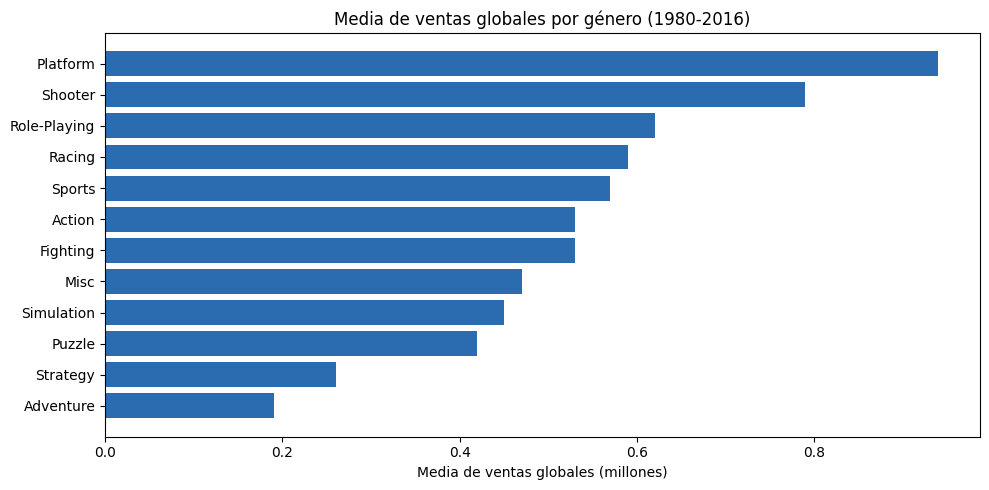

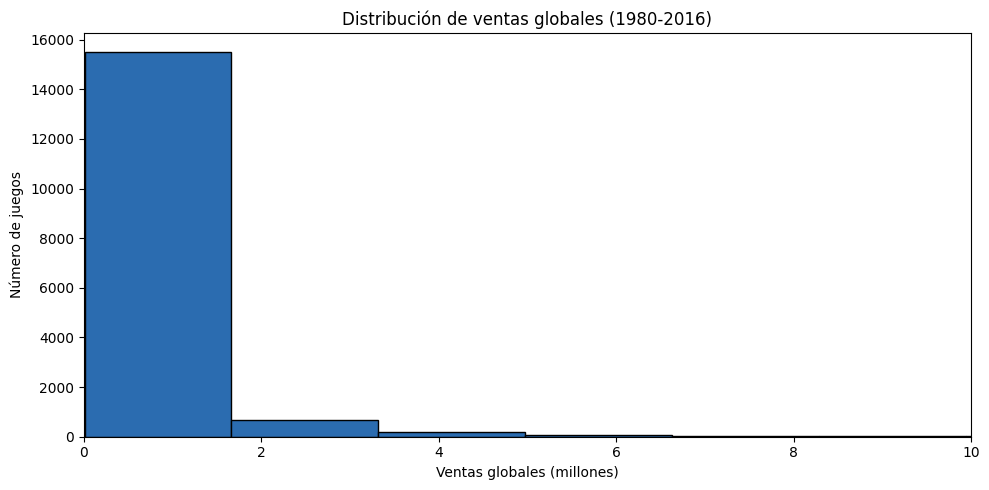

In [32]:
import matplotlib.pyplot as plt   ##PARA LA PFRESENTACION

# Gráfico 1: Media de ventas por género
fig, ax = plt.subplots(figsize=(10, 5))
medida_1_sorted = medida_1.sort_values("media_global", ascending=True)
ax.barh(medida_1_sorted["Genre"], medida_1_sorted["media_global"], color="#2b6cb0")
ax.set_xlabel("Media de ventas globales (millones)")
ax.set_title("Media de ventas globales por género (1980-2016)")
plt.tight_layout()
plt.savefig("grafico_genero.png", dpi=150)
plt.show()

# Gráfico 2: Histograma de ventas globales
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(listos["Global_Sales"], bins=50, color="#2b6cb0", edgecolor="black")
ax.set_xlabel("Ventas globales (millones)")
ax.set_ylabel("Número de juegos")
ax.set_title("Distribución de ventas globales (1980-2016)")
ax.set_xlim(0, 10)
plt.tight_layout()
plt.savefig("grafico_ventas.png", dpi=150)
plt.show()